# Qwen repair calibration: staged rerun
## Did explicit turn-taking fix the calibration workflow?

The initial Qwen session proposed all four batches and an edit before receiving feedback, so it was incomplete. A **fresh** session used a revised prompt that explicitly required one batch, then a pause for results. This notebook reports that second session and keeps the original failure visible.

These are calibration observations on a deliberately weakened handcrafted model—not a matched main-study comparison or held-out result. The Qwen rerun used a different prompt version from Astra's initial calibration.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT=Path.cwd().resolve()
if not (ROOT/'experiment.json').exists(): ROOT=ROOT.parent
if not (ROOT/'experiment.json').exists(): raise FileNotFoundError('Open this notebook from the project root or notebooks/.')
data=json.loads((ROOT/'results/repair_calibration_results.json').read_text())
initial=data['sessions'][1]; revised=data['revised_sessions'][0]
probe_dir=ROOT/'responses'/'probes'/revised['session_id']
rounds=[json.loads((probe_dir/f'round-{i}.json').read_text()) for i in range(1,5)]
OUT=ROOT/'results'/'figures'; OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':300,'font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'axes.titleweight':'bold','figure.facecolor':'white'})
def save(fig,name):
    fig.savefig(OUT/f'{name}.png',bbox_inches='tight',facecolor='white')
    fig.savefig(OUT/f'{name}.svg',bbox_inches='tight',facecolor='white')
print('Revised Qwen session:',revised['status'],'; delivered probe rounds:',len(rounds))
print('No held-out evaluation data was used.')

Revised Qwen session: completed_with_accepted_token_overrun ; delivered probe rounds: 4
No held-out evaluation data was used.


## 1. The staged prompt changed the interaction

The revised prompt asked for exactly one JSON batch per turn, then an explicit stop until feedback. In the initial session, Qwen returned all batches and a final proposal at once. In the revised session, it returned four batches over four turns, received each batch of logits, and then submitted a final edit.

This single rerun is consistent with the revised instructions helping, but it does not prove that the prompt change alone caused the improvement; model responses can vary between runs.

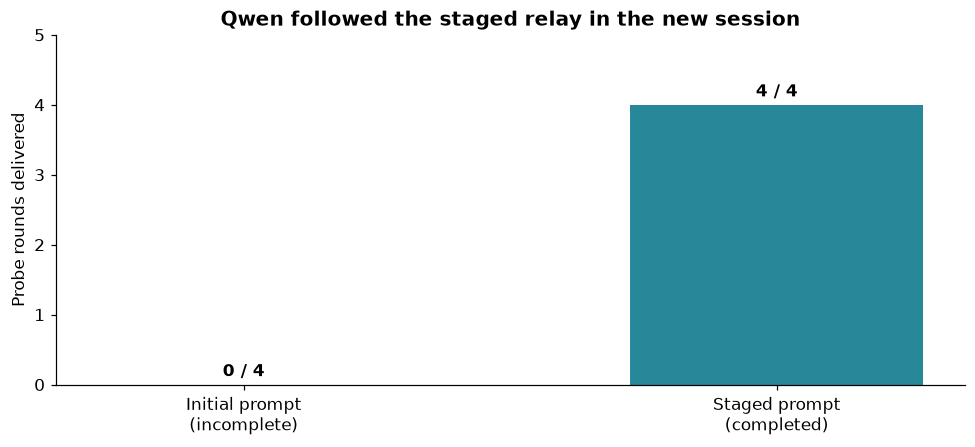

In [2]:
fig,ax=plt.subplots(figsize=(9,4.2))
labels=['Initial prompt\n(incomplete)','Staged prompt\n(completed)']
values=[initial['probe_rounds_delivered'],revised['probe_rounds_delivered']]
bars=ax.bar(labels,values,color=['#d47743','#27889a'],width=.55)
for b in bars: ax.text(b.get_x()+b.get_width()/2,b.get_height()+.12,f'{b.get_height():.0f} / 4',ha='center',weight='bold')
ax.set(ylim=(0,5),ylabel='Probe rounds delivered',title='Qwen followed the staged relay in the new session')
fig.tight_layout(); save(fig,'23_qwen_staged_rounds'); plt.show()

## 2. Proposal and development-validation result

After the fourth feedback batch, Qwen proposed multiplying `fc2.weight[0,0]` by 2—the inverse of the deliberately introduced calibration fault. On the same 1,024 validation examples, this improved overall accuracy from 91.50% to 100%, including an increase from 66.02% to 100% in Q++.

The proposal was frozen before this validation comparison. These are development results; the main cohort has not been frozen or evaluated.

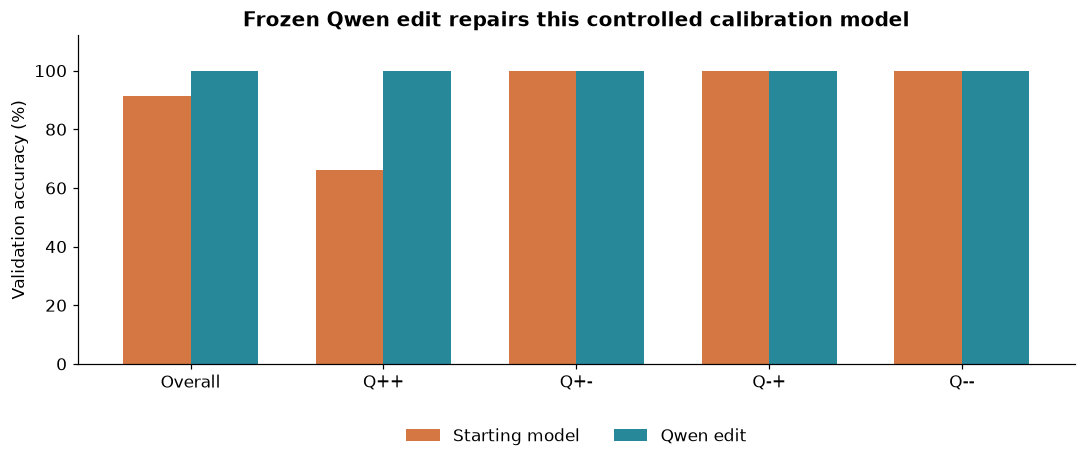

Edit: {'parameter': 'fc2.weight', 'index': [0, 0], 'scale': 2.0}
Accuracy change: +8.50 percentage points


In [3]:
before,after=revised['before'],revised['after']; labels=['Overall','Q++','Q+-','Q-+','Q--']
left=[before['accuracy']]+[before['quadrants'][q]['accuracy'] for q in labels[1:]]
right=[after['accuracy']]+[after['quadrants'][q]['accuracy'] for q in labels[1:]]
fig,ax=plt.subplots(figsize=(10,4.4)); x=np.arange(len(labels)); w=.35
ax.bar(x-w/2,np.array(left)*100,w,label='Starting model',color='#d47743')
ax.bar(x+w/2,np.array(right)*100,w,label='Qwen edit',color='#27889a')
ax.set(xticks=x,xticklabels=labels,ylim=(0,112),ylabel='Validation accuracy (%)',title='Frozen Qwen edit repairs this controlled calibration model')
ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2)
fig.tight_layout(); save(fig,'24_qwen_staged_validation'); plt.show()
print('Edit:',revised['proposal'])
print('Accuracy change:',f"{revised['accuracy_change']*100:+.2f} percentage points")

## 3. Check the explanation as well as the edit

Qwen's final explanation said zero-coordinate cases were unchanged. That claim is not true for the **logit**: at x = (0.5, 0, 0, 0), the original model outputs −1.25 and the edited model outputs 0. Both still predict class 0, because class 1 requires a positive logit. The edit succeeds on the validation accuracy metric even though this part of the explanation is incorrect.

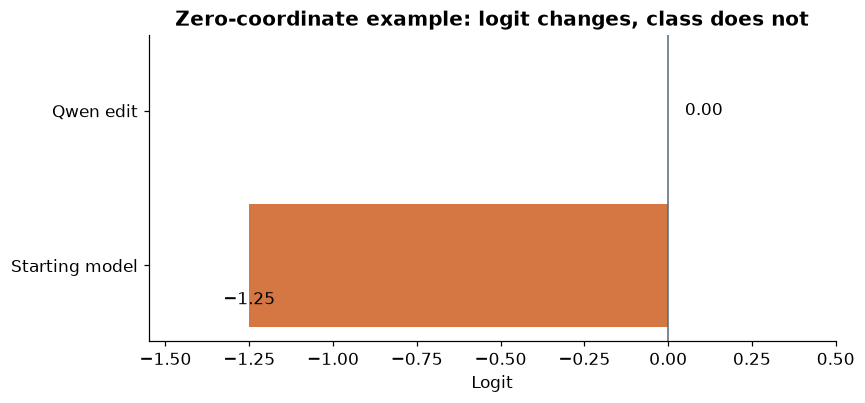

The proposal claimed zero-coordinate cases were unchanged. This example changes the logit while remaining class 0.


In [4]:
case=revised['interpretation_correction']
fig,ax=plt.subplots(figsize=(8,3.8))
bars=ax.barh(['Starting model','Qwen edit'],[case['before_logit'],case['after_logit']],color=['#d47743','#27889a'])
ax.axvline(0,color='#536a74',lw=1)
ax.set(xlim=(-1.55,.5),xlabel='Logit',title='Zero-coordinate example: logit changes, class does not')
ax.text(-1.25,-.25,'−1.25',ha='center'); ax.text(.05,1,'0.00',va='center')
fig.tight_layout(); save(fig,'25_qwen_explanation_check'); plt.show()
print(case['note'])

## 4. Token accounting and limitations

The first revised response was a valid single probe batch, but OpenRouter reported **4,832 completion tokens** against the requested 4,096-token maximum. The user had accepted this type of overrun. Its reported $0.01524 cost was below its $0.08145 reservation, so the already-returned response was explicitly reconciled in a separate audit record without sending it again. Later calls completed normally.

OpenRouter reported **$0.04494** for the five revised Qwen calls. The total local reservation ledger after the rerun is $8.70395 of $10; reservations are not actual spend or a provider-side billing guarantee. The reason the first reported token count exceeded the requested limit remains unverified. The original incomplete session, its response, and the revised session are all preserved.

The revised calibration shows that Qwen can complete this staged workflow on the controlled circuit under the recorded settings. It does not establish that probing caused the repair, that the explanation is entirely correct, or that the result generalizes to a trained model. The main comparison should use a common finalized prompt and a predeclared study plan.